In [2]:
from pathlib import Path
import subprocess
import sys
from google.colab import drive

DRIVE = Path('/content/drive')
drive.mount('/content/drive')

ROOT = DRIVE / "MyDrive" / "doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval"
assert ROOT.exists()
PACKAGE_DIR = ROOT / 'python_packages'
PACKAGE_DIR.mkdir(exist_ok=True)

sys.path.insert(0, str(PACKAGE_DIR))
print(PACKAGE_DIR.resolve())

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.ticker import FuncFormatter, NullFormatter, FixedLocator
import cartopy.feature as cfeature
import numpy as np
import string
import gc

sys.path.insert(0, str(ROOT / "src"))

DATA_ROOT = ROOT / "data"
PREDS_ROOT = ROOT/ "outputs" / "aa_geoph_fluids"

VAR_DS = "precip"

NFES = [5, 10, 25, 50, 100, 250, 500]

FIGS_PATH = ROOT / "figures" / "nfe_analysis"
FIGS_PATH.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/.shortcut-targets-by-id/1WkHyL_6hJDy8RansGc0sPwwdfLfvykxM/doctorado/materias/ml_geofluidos_inv/tp_final/codigos_eval/python_packages


In [3]:
def plot_models_nfe(data, var_label="precip", cmap="Blues",
                     vmin=None, vmax=None, extend_pad=0.0,
                     figsize_por_panel=(3.2, 2.8), savepath=None, title=None):
    modelos = list(data.keys())
    n_rows = len(modelos)
    n_cols = max(da.sizes["nfe"] for da in data.values())

    if vmin is None:
        vmin = min(float(da.min()) for da in data.values())
    if vmax is None:
        vmax = max(float(da.quantile(0.99)) for da in data.values())

    proj = ccrs.PlateCarree()
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(figsize_por_panel[0] * n_cols, figsize_por_panel[1] * n_rows + 2),
        subplot_kw={"projection": proj},
        squeeze=False,
    )

    da0 = data[modelos[0]]
    lon_min, lon_max = float(da0.lon.min()), float(da0.lon.max())
    lat_min, lat_max = float(da0.lat.min()), float(da0.lat.max())
    extent = [lon_min - extend_pad, lon_max + extend_pad,
              lat_min - extend_pad, lat_max + extend_pad]

    mesh = None
    for i, model in enumerate(models):
        da = data[model]
        for j in range(n_cols):
            ax = axes[i, j]
            if j >= da.sizes["nfe"]:
                ax.set_visible(False)
                continue

            campo = da.isel(nfe=j)
            mesh = ax.pcolormesh(
                campo.lon, campo.lat, campo.values,
                transform=proj, cmap=cmap, vmin=vmin, vmax=vmax,
                shading="auto",
            )
            ax.set_extent(extent, crs=proj)
            ax.coastlines(resolution="50m", linewidth=0.6)
            ax.add_feature(cfeature.BORDERS, linewidth=0.4)

            gl = ax.gridlines(draw_labels=True, linewidth=0.3,
                              color="gray", alpha=0.5, linestyle="--")
            gl.top_labels = False
            gl.right_labels = False
            gl.left_labels = (j == 0)
            gl.bottom_labels = (i == n_rows - 1)
            gl.xlabel_style = {"size": 7}
            gl.ylabel_style = {"size": 7}

            if i == 0:
                nfe_val = da.nfe.values[j] if "nfe" in da.coords else j
                ax.set_title(f"nfe = {nfe_val}", fontsize=10)

            if j == 0:
                ax.text(-0.28, 0.5, model, transform=ax.transAxes,
                        rotation=90, va="center", ha="center",
                        fontsize=11, fontweight="bold")

    cbar = fig.colorbar(mesh, ax=axes, orientation="horizontal",
                        fraction=0.04, pad=0.06, shrink=0.6, extend="max")
    cbar.set_label(var_label)

    if title:
        fig.suptitle(title, weight="bold")

    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig, axes

import numpy as np
import matplotlib.pyplot as plt


def plot_violins_nfe(data, var_label="precip", n_cols_panel=None,
                      sharey=True, log=False, color="#eda100", title=None,
                      target_value=None,
                      figsize_por_panel=(4.5, 3.5), savepath=None):
    models = list(data.keys())
    n = len(models)
    n_cols_panel = n_cols_panel or min(n, 3)
    n_rows_panel = int(np.ceil(n / n_cols_panel))

    fig, axes = plt.subplots(
        n_rows_panel, n_cols_panel,
        figsize=(figsize_por_panel[0] * n_cols_panel,
                 figsize_por_panel[1] * n_rows_panel),
        sharey=sharey, squeeze=False,
    )
    axes_flat = axes.ravel()

    for k, model in enumerate(models):
        ax = axes_flat[k]
        da = data[model]
        nfe_vals = da.nfe.values if "nfe" in da.coords else np.arange(da.sizes["nfe"])

        samples = []
        for j in range(da.sizes["nfe"]):
            v = da.isel(nfe=j).values.ravel()
            v = v[np.isfinite(v)]
            if log:
                v = np.log10(v[v > 0])
            samples.append(v)

        pos = np.arange(1, len(samples) + 1)
        vp = ax.violinplot(samples, positions=pos, widths=0.8,
                              showmedians=True, showextrema=False)
        for body in vp["bodies"]:
            body.set_facecolor(color); body.set_edgecolor(color); body.set_alpha(0.55)

        vp["cmedians"].set_color("#222221"); vp["cmedians"].set_linewidth(1.5)

        ax.set_xticks(pos)
        ax.set_xticklabels([str(x) for x in nfe_vals])
        ax.set_xlabel("nfe")
        ax.set_title(model, fontweight="bold")
        ax.grid(axis="y", alpha=0.3)
        if k % n_cols_panel == 0:
            ax.set_ylabel(f"log10({var_label})" if log else var_label)

        if target_value:
            ax.axhline(target_value, color="0.4", lw=1, ls="--", zorder=0)

    for ax in axes_flat[n:]:
        ax.set_visible(False)


    if title:
        fig.suptitle(title, weight="bold")
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig, axes

In [4]:
def open_nfe_sims(model):
    path = PREDS_ROOT / model / "extreme_days"
    list_datasets = []
    for nfe in NFES:
        fname = path / f"simulations_extreme_days_nfe{nfe}.nc"
        list_datasets.append(
            xr.open_dataset(
                fname,
            ).expand_dims(dim={"nfe": [nfe]})
        )
    return xr.concat(list_datasets, dim="nfe")


models = ["DDPM", "FlowMatch"]

preds_models = {m: open_nfe_sims(m)[VAR_DS] for m in models }

da_y_test = xr.open_dataset(DATA_ROOT / "predictands" / f"pr_SESA_ERA5.nc").sel(
    time=preds_models[models[0]].time.values
)[VAR_DS]

## RMSE

In [5]:
def rmse(preds, target, pool_members=True):
    preds = preds.copy()
    if pool_members and ("member" in preds.dims):
        preds = preds.mean("member")

    rmse = np.sqrt( ( (preds - target) ** 2 ).mean(dim="time"))
    return rmse

rmse_result = { m: rmse(preds_models[m], da_y_test) for m in models }

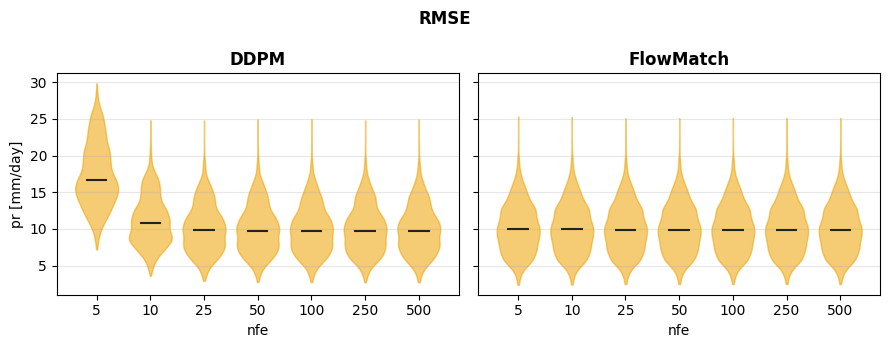

In [6]:
# fig_maps_rmse, axes = plot_models_nfe(rmse_result, var_label="pr [mm/day]", title="RMSE"); plt.show()

fig_violin_rmse, axes = plot_violins_nfe(rmse_result, var_label="pr [mm/day]", title="RMSE")
fig_violin_rmse.savefig(FIGS_PATH / "rmse.png", dpi=500, bbox_inches="tight")
plt.show()

### Spread

In [7]:
def spread(preds):
    preds = preds.copy()
    m = preds.sizes["member"]
    ensemble_mean = preds.mean(dim="member")
    variance = ((preds - ensemble_mean)**2).sum(dim="member") / (m - 1)
    variance *= (m + 1) / m
    return np.sqrt(variance.mean(dim="time"))

spead_results = {
    m: spread(preds_models[m])
    for m in models
}

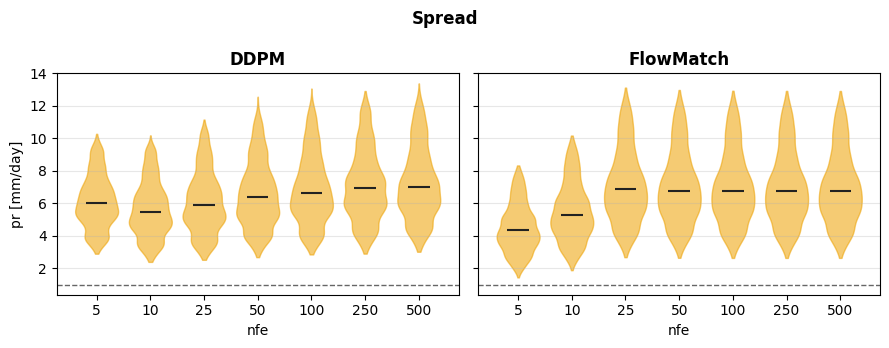

In [8]:
fig_violin_spead_skill, axes = plot_violins_nfe(spead_results, var_label="pr [mm/day]",
                              title="Spread",
                              target_value=1.0)
fig_violin_spead_skill.savefig(FIGS_PATH / "spread.png", dpi=500, bbox_inches="tight")
plt.show()

## Spread-to-rmse ratio

In [9]:
s2rmse_results = {
    m: spead_results[m] / rmse_result[m]
    for m in models
}

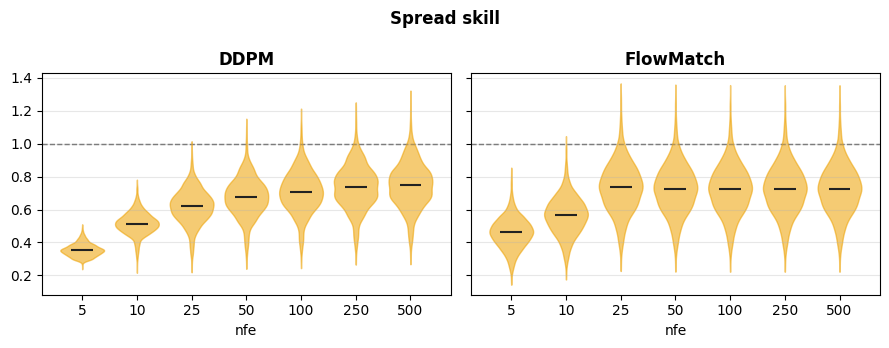

In [10]:
# fig, axes = plot_modelos_nfe(s2rmse_results, var_label="", title="spread-to-noise ratio"); plt.show()

fig_violin_spead_skill, axes = plot_violins_nfe(s2rmse_results, var_label="",
                              title="Spread skill",
                              target_value=1.0)
fig_violin_spead_skill.savefig(FIGS_PATH / "spread-skill.png", dpi=500, bbox_inches="tight")
plt.show()

## CRPSS

In [11]:
from statistical_downscaling.evaluation.metrics.univariate.probabilistic import (
    crpss, crps_ensemble, climatological_reference
)

gc.collect()

crps_results = {
    m: crps_ensemble(preds_models[m], da_y_test, time_chunk=4)
    for m in models
}

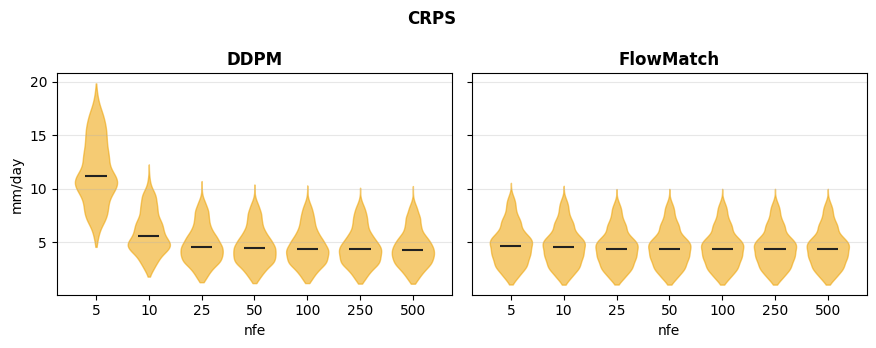

In [12]:
# fig, axes = plot_modelos_nfe(crps_results, var_label="mm/day", title="CRPS"); plt.show()

fig_violin_crps, axes = plot_violins_nfe(crps_results, var_label="mm/day",  title="CRPS", target_value=0.0)
fig_violin_crps.savefig(FIGS_PATH / "crps.png", dpi=500, bbox_inches="tight")
plt.show()

## RALSD

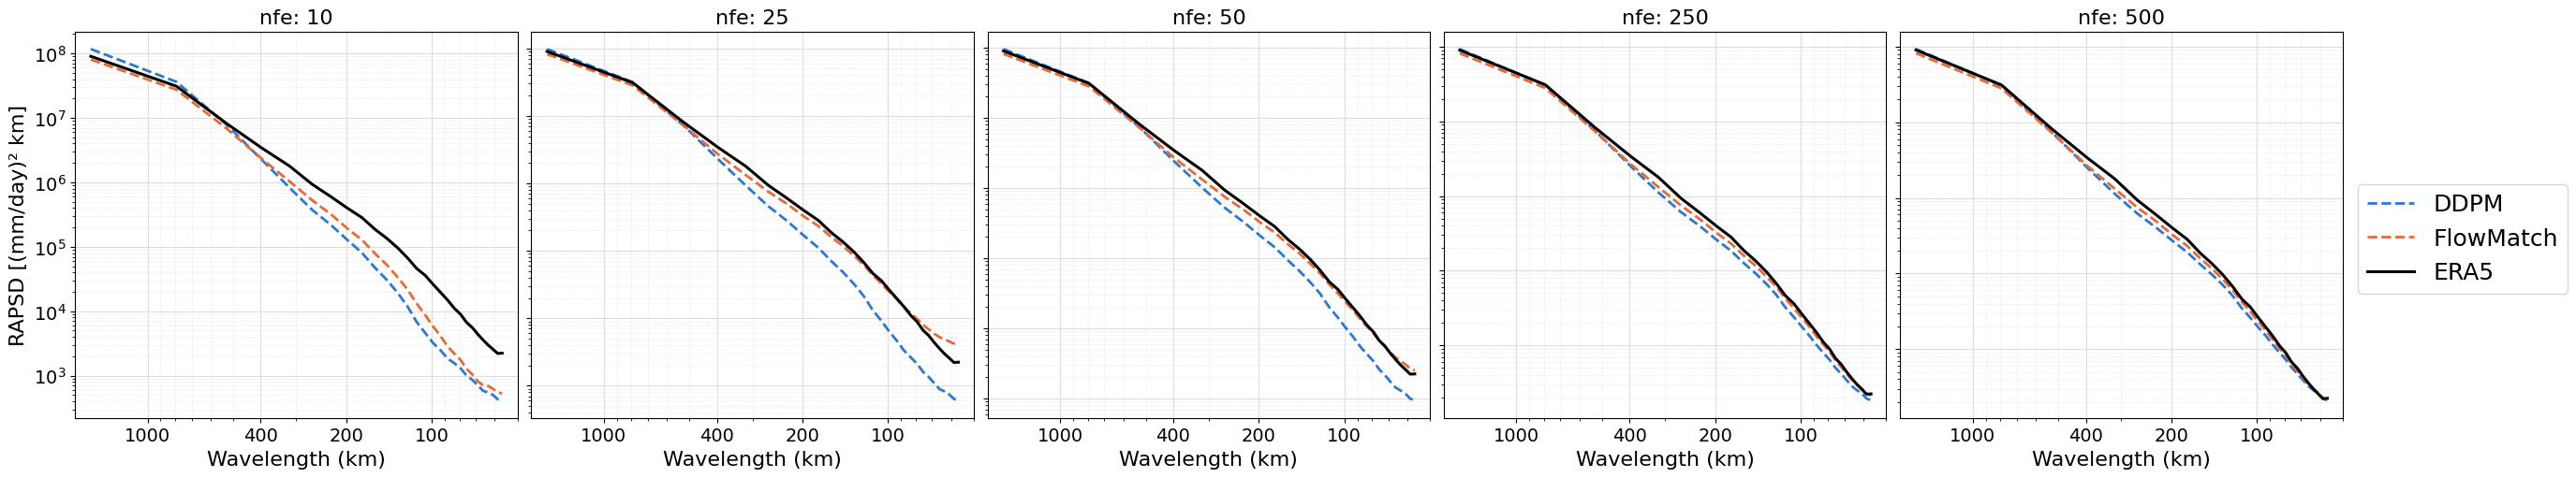

In [20]:
import statistical_downscaling.evaluation.stats.univariate.ralsd as ralsd
to_rapsd = lambda p: p / (2 * np.pi * p["k"])
MIN_WL = 50

E_ref = ralsd.isotropic_psd(da_y_test).compute()
psd_ref = ralsd.psd_mean(E_ref)
rapsd_ref = to_rapsd(psd_ref)

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]


def _wavelength_axis(ax, lam, ticks, xlim):
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator([t for t in ticks if lam.min() <= t <= lam.max()]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(*xlim)
    ax.set_xlabel("Wavelength (km)",  fontsize=16)
    ax.tick_params(axis="both", which="major", labelsize=14)
    ax.tick_params(axis="both", which="minor", labelsize=12)

def plot_rapsd(psd_ref, psd_mod: dict, ref_name="Reference", units="",
               title="Radially Averaged Power Spectral Density", ax=None,
               ticks=(1000, 400, 200, 100, 50), xlim=(1800, 50), colors: dict | None = None):
    """psd_ref: DataArray (k); psd_mod: {modelo: DataArray (k)}. Log-log."""
    colors = colors or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 5), constrained_layout=True)

    for i, (m, p) in enumerate(psd_mod.items()):
        ax.plot(p["wavelength"], p, lw=2, label=m,ls="--",
                color=colors.get(m, SERIES_COLORS[i % len(SERIES_COLORS)]))
    ax.plot(psd_ref["wavelength"], psd_ref, color="k", lw=2.2, ls="-", label=ref_name, zorder=5)

    ax.set_yscale("log")
    _wavelength_axis(ax, psd_ref["wavelength"], ticks, xlim)
    u = f" [({units})² km]" if units else ""
    ax.set_ylabel(f"RAPSD{u}", fontsize=16)
    if title:
        ax.set_title(title, fontweight="bold")
    # ax.legend(frameon=True, fontsize=9)
    ax.grid(which='major', color='#DDDDDD', linewidth=0.8)
    ax.grid(which='minor', color='#DDDDDD', linestyle=':', linewidth=0.5)
    return ax

LAMBDA_MAX = 1600

def _wl_psd(r):
    if isinstance(r, tuple):
        return np.asarray(r[0]), np.asarray(r[1])

    dim = r.dims[0]
    return np.asarray(r[dim].values), np.asarray(r.values)

def log_ratio_error(rapsd_m, rapsd_ref, lambda_max=LAMBDA_MAX):
    wl_m, p_m = _wl_psd(rapsd_m)
    wl_r, p_r = _wl_psd(rapsd_ref)
    assert np.allclose(wl_m, wl_r), "The longitude of the waves do not coincide"
    mask = (wl_m < lambda_max) & (p_m > 0) & (p_r > 0)
    return np.mean(np.abs(np.log10(p_m[mask] / p_r[mask])))


spec_err = {m: [] for m in preds_models}

fig, axes = plt.subplots(1, len(NFES), figsize=(25, 5), constrained_layout=True)

for j, nfe in enumerate(NFES):

    E_mod = {m: ralsd.isotropic_psd(d.sel(nfe=nfe)).compute()
            for m, d in preds_models.items()}


    psd_mod = {m: ralsd.psd_mean(E) for m, E in E_mod.items()}
    ratios  = {m: ralsd.psd_ratio(E, E_ref) for m, E in E_mod.items()}
    rapsd_mod = {m: to_rapsd(p) for m, p in psd_mod.items()}

    for m in preds_models:
        spec_err[m].append(log_ratio_error(rapsd_mod[m], rapsd_ref))

    ax = plot_rapsd(rapsd_ref, rapsd_mod, ref_name="ERA5", units="mm/day", ax=axes[j])
    axes[j].set_title(f"nfe: {nfe}", size=16)
    if j>0:
      axes[j].set_ylabel("")
      axes[j].set_yticklabels("")


fig.savefig(FIGS_PATH / "rapsd.png", dpi=400, bbox_inches="tight")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5),
           frameon=True, fontsize=18)
plt.show()

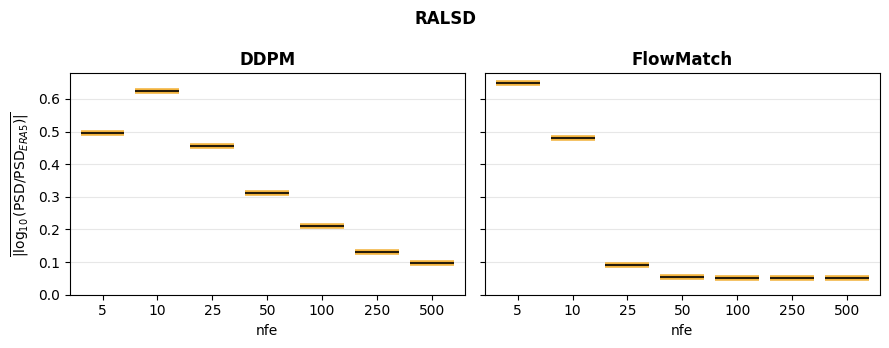

In [18]:

width = 0.8
ylabel = r"$\overline{|\log_{10}(\mathrm{PSD}/\mathrm{PSD}_{ERA5})|}$"

fig, axes = plt.subplots(1, len(models), figsize=(4.5 * len(models), 3.5),
                             sharey=True, squeeze=False)
pos = np.arange(1, len(NFES) + 1)
for ax, m in zip(axes[0], models):
    v = np.asarray(spec_err[m])
    ax.hlines(v, pos - width / 2, pos + width / 2, color="#F2B33D", lw=4)
    ax.hlines(v, pos - width / 2, pos + width / 2, color="black", lw=1.2)
    ax.set_xticks(pos)
    ax.set_xticklabels([str(n) for n in NFES])
    ax.set_xlim(0.4, len(NFES) + 0.6)
    ax.set_xlabel("nfe")
    ax.set_title(m, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
axes[0, 0].set_ylabel(ylabel)
axes[0, 0].set_ylim(bottom=0)
fig.suptitle(f"RALSD", fontweight="bold")
fig.tight_layout()

fig.savefig(FIGS_PATH / "psd_error.png", dpi=500, bbox_inches="tight")
plt.show()

DDPM nfe=5 listo
DDPM nfe=10 listo
DDPM nfe=25 listo
DDPM nfe=50 listo
DDPM nfe=100 listo
DDPM nfe=250 listo
DDPM nfe=500 listo
FlowMatch nfe=5 listo
FlowMatch nfe=10 listo
FlowMatch nfe=25 listo
FlowMatch nfe=50 listo
FlowMatch nfe=100 listo
FlowMatch nfe=250 listo
FlowMatch nfe=500 listo


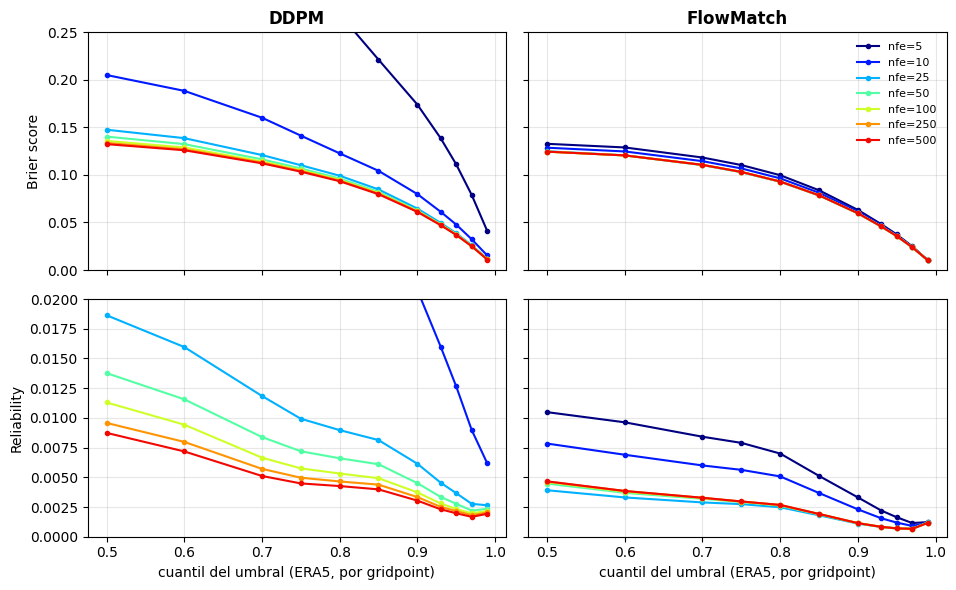

In [26]:
from scipy.ndimage import uniform_filter

QS_DEFAULT = np.array([0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.93, 0.95, 0.97, 0.99])

def _brier_murphy(P, O, n_bins=10):
    P, O = P.ravel(), O.ravel()
    N = P.size
    bs = np.mean((P - O) ** 2)

    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(P, edges[1:-1]), 0, n_bins - 1)
    n_k = np.bincount(idx, minlength=n_bins)
    sp_k = np.bincount(idx, weights=P, minlength=n_bins)
    so_k = np.bincount(idx, weights=O, minlength=n_bins)
    ok = n_k > 0
    pbar = sp_k[ok] / n_k[ok]
    obar_k = so_k[ok] / n_k[ok]
    obar = O.mean()

    rel = np.sum(n_k[ok] * (pbar - obar_k) ** 2) / N
    res = np.sum(n_k[ok] * (obar_k - obar) ** 2) / N
    unc = obar * (1 - obar)
    return bs, rel, res, unc


def _fss(P, O, size):
    Pf = uniform_filter(P, size=(1, size, size), mode="constant")
    Of = uniform_filter(O.astype(float), size=(1, size, size), mode="constant")
    mse = np.mean((Pf - Of) ** 2)
    mse_ref = np.mean(Pf ** 2) + np.mean(Of ** 2)
    return 1 - mse / mse_ref if mse_ref > 0 else np.nan


def scores_por_cuantil(preds_models, target, qs=QS_DEFAULT,
                       fss_sizes=(3, 9), n_bins=10):
    qs = np.asarray(qs)
    modelos = list(preds_models.keys())
    nfes = preds_models[modelos[0]].nfe.values

    times = preds_models[modelos[0]].time
    obs = target.sel(time=times).transpose("time", "lat", "lon")
    thr = obs.quantile(qs, dim="time").values
    obs_v = obs.values

    shape = (len(modelos), len(nfes), len(qs))
    out = {k: np.full(shape, np.nan) for k in ["bs", "rel", "res", "unc"]}
    for s in fss_sizes:
        out[f"fss_{s}"] = np.full(shape, np.nan)

    for i, m in enumerate(modelos):
        da = preds_models[m]
        for j, nfe in enumerate(nfes):
            p = da.sel(nfe=nfe).transpose("time", "member", "lat", "lon").values
            for k in range(len(qs)):
                t = thr[k]
                P = (p > t).mean(axis=1)
                O = (obs_v > t).astype(float)
                bs, rel, res, unc = _brier_murphy(P, O, n_bins=n_bins)
                out["bs"][i, j, k] = bs
                out["rel"][i, j, k] = rel
                out["res"][i, j, k] = res
                out["unc"][i, j, k] = unc
                for s in fss_sizes:
                    out[f"fss_{s}"][i, j, k] = _fss(P, O, s)
            print(f"{m} nfe={nfe} listo")

    coords = {"model": modelos, "nfe": nfes, "q": qs}
    return xr.Dataset({k: (("model", "nfe", "q"), v) for k, v in out.items()},
                      coords=coords)

def plot_scores_cuantil(ds, fss_size=9, cmap="jet", savepath=None):
    filas = [
        (ds.bs, "Brier score"),
        (ds.rel, "Reliability"),
        # (ds[f"fss_{fss_size}"], f"FSS ({fss_size}x{fss_size})"),
    ]
    modelos = ds.model.values
    nfes = ds.nfe.values
    colors = plt.get_cmap(cmap)(np.linspace(0, 0.9, len(nfes)))

    fig, axes = plt.subplots(len(filas), len(modelos),
                             figsize=(4.8 * len(modelos), 3.0 * len(filas)),
                             sharex=True, sharey="row", squeeze=False)
    for r, (var, ylabel) in enumerate(filas):

        for c, m in enumerate(modelos):
            ax = axes[r, c]
            for n, col in zip(nfes, colors):
                ax.plot(ds.q, var.sel(model=m, nfe=n), "-o", ms=3,
                        color=col, label=f"nfe={n}")
            ax.grid(alpha=0.3)
            if r == 0:
                ax.set_title(m, fontweight="bold")
            if c == 0:
                ax.set_ylabel(ylabel)
            if r == len(filas) - 1:
                ax.set_xlabel("cuantil del umbral (ERA5, por gridpoint)")
        if ylabel == "Brier score":
            ax.set_ylim(0, 0.25)
        if ylabel == "Reliability":
            ax.set_ylim(0, 0.02)
    axes[0, -1].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig, axes





ds_scores = scores_por_cuantil(preds_models, da_y_test)
plot_scores_cuantil(ds_scores, fss_size=9)
plt.show()

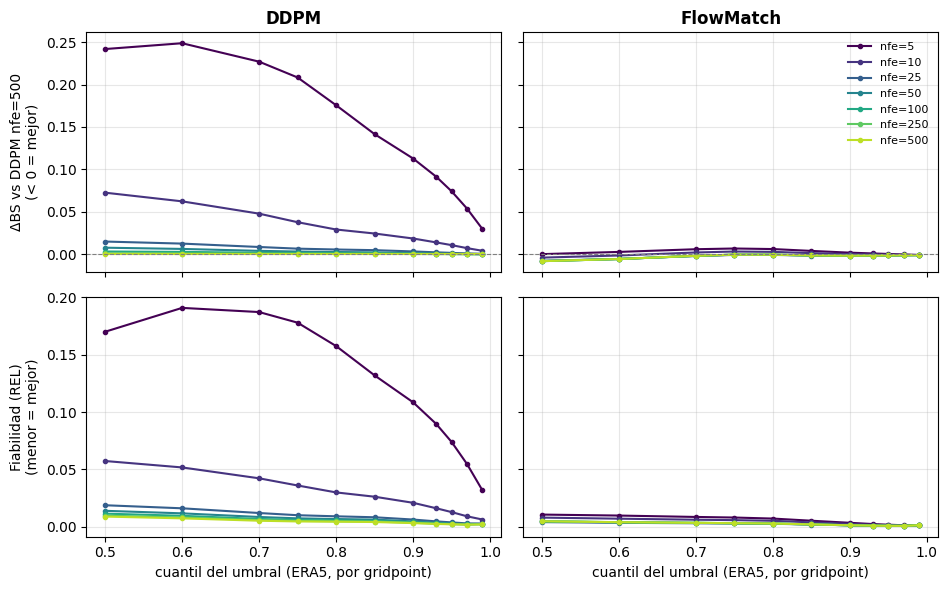

In [23]:
def plot_scores_cuantil(ds, ref_model="DDPM", ref_nfe=None, fss_size=9,
                        cmap="viridis", savepath=None):
    ref_nfe = ref_nfe if ref_nfe is not None else ds.nfe.values.max()
    bs_ref = ds.bs.sel(model=ref_model, nfe=ref_nfe)
    dbs = ds.bs - bs_ref

    filas = [
        (dbs, f"ΔBS vs {ref_model} nfe={ref_nfe}\n(< 0 = mejor)", True),
        (ds.rel, "Fiabilidad (REL)\n(menor = mejor)", False),
        # (ds[f"fss_{fss_size}"], f"FSS ({fss_size}×{fss_size})\n(mayor = mejor)", False),
    ]
    modelos = ds.model.values
    nfes = ds.nfe.values
    colors = plt.get_cmap(cmap)(np.linspace(0, 0.9, len(nfes)))

    fig, axes = plt.subplots(len(filas), len(modelos),
                             figsize=(4.8 * len(modelos), 3.0 * len(filas)),
                             sharex=True, sharey="row", squeeze=False)
    for r, (var, ylabel, linea_cero) in enumerate(filas):
        for c, m in enumerate(modelos):
            ax = axes[r, c]
            for n, col in zip(nfes, colors):
                ax.plot(ds.q, var.sel(model=m, nfe=n), "-o", ms=3,
                        color=col, label=f"nfe={n}")
            if linea_cero:
                ax.axhline(0, color="gray", ls="--", lw=0.8)
            ax.grid(alpha=0.3)
            if r == 0:
                ax.set_title(m, fontweight="bold")
            if c == 0:
                ax.set_ylabel(ylabel)
            if r == len(filas) - 1:
                ax.set_xlabel("cuantil del umbral (ERA5, por gridpoint)")
    axes[0, -1].legend(fontsize=8, frameon=False)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig, axes


plot_scores_cuantil(ds_scores, ref_model="DDPM", fss_size=9)
plt.show()
